# **Day 89: Project - Analysing One Year of Real Weather Data**

In this project, we download **real daily weather data** for 2023 from the free **Open-Meteo historical weather API**, and analyse it with Pandas and Matplotlib.

The data comes from **ERA5**, a global weather dataset made by combining satellite observations, weather stations and computer models. It is widely used in climate and Remote Sensing research.

**Questions:**
1. How do temperature and rainfall change through the year in Kolkata?
2. When was the hottest period?
3. How much of the rain falls in the monsoon?
4. How do Kolkata, Siliguri, Darjeeling and Midnapore compare?

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def get_year(lat, lon, year):
    """Download one year of daily weather for a location."""
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": lat, "longitude": lon,
        "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,relative_humidity_2m_mean",
        "timezone": "Asia/Kolkata",
    }, timeout=30)
    r.raise_for_status()
    d = pd.DataFrame(r.json()["daily"])
    d["time"] = pd.to_datetime(d["time"])
    return d.set_index("time").rename(columns={
        "temperature_2m_max": "tmax", "temperature_2m_min": "tmin",
        "precipitation_sum": "rain", "relative_humidity_2m_mean": "humidity"})

cities = {"Kolkata": (22.57, 88.36), "Siliguri": (26.73, 88.40),
          "Darjeeling": (27.04, 88.27), "Midnapore": (22.43, 87.32)}
data = {city: get_year(*ll, 2023) for city, ll in cities.items()}

kolkata = data["Kolkata"]
print(kolkata.shape)
kolkata.head()

(365, 4)


,tmax,tmin,rain,humidity
time,,,,
2023-01-01,24.7,15.8,0.2,83
2023-01-02,25.7,15.5,0.0,73
2023-01-03,25.2,14.7,0.0,72
2023-01-04,24.0,13.5,0.0,75
2023-01-05,23.1,12.2,0.0,70


In [2]:
kolkata.describe().round(1)

,tmax,tmin,rain,humidity
count,365.0,365.0,365.0,365.0
mean,31.7,22.4,5.2,75.8
std,3.9,4.7,8.8,11.1
min,21.7,10.4,0.0,37.0
25%,29.6,19.2,0.0,71.0
50%,31.7,24.1,0.2,76.0
75%,33.6,26.1,7.1,85.0
max,42.6,30.6,44.6,94.0


## **Question 1: Monthly Pattern**

In [3]:
monthly = kolkata.resample("ME").agg({"tmax": "mean", "tmin": "mean", "rain": "sum", "humidity": "mean"}).round(1)
monthly.index = monthly.index.strftime("%b")
monthly

,tmax,tmin,rain,humidity
time,,,,
Jan,26.3,14.6,0.8,73.3
Feb,30.2,18.0,0.8,65.0
Mar,32.4,21.2,106.6,67.0
Apr,36.8,24.5,58.3,63.1
May,35.9,25.8,142.6,73.6
Jun,35.4,27.6,302.7,80.4
Jul,32.2,26.4,282.2,85.5
Aug,32.4,26.3,397.2,85.1
Sep,31.4,25.7,377.9,88.4


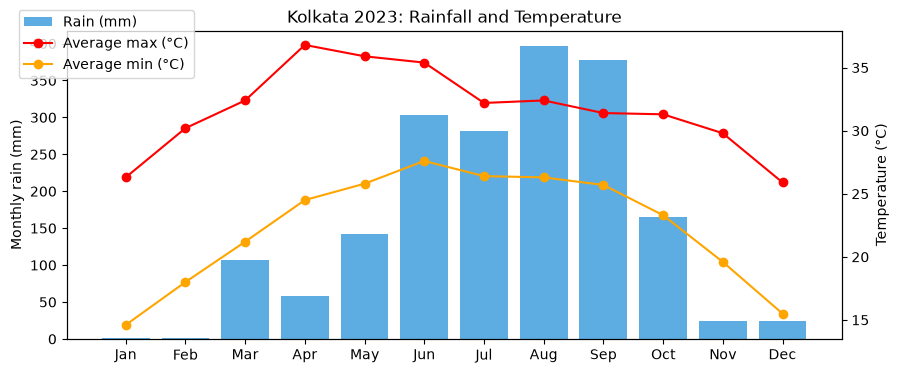

In [4]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(monthly.index, monthly["rain"], color="#5dade2", label="Rain (mm)")
ax1.set_ylabel("Monthly rain (mm)")

ax2 = ax1.twinx()                            # A second y-axis on the right side
ax2.plot(monthly.index, monthly["tmax"], "r-o", label="Average max (°C)")
ax2.plot(monthly.index, monthly["tmin"], "-o", color="orange", label="Average min (°C)")
ax2.set_ylabel("Temperature (°C)")

fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.95))
ax1.set_title("Kolkata 2023: Rainfall and Temperature")
plt.show()

- `ax1.twinx()` makes a second chart that shares the same x-axis but has its own y-axis. This lets us show rain (mm) and temperature (°C) together.

## **Question 2: The Hottest Days and the Heatwave**

In [5]:
print(kolkata.nlargest(5, "tmax")[["tmax", "tmin", "humidity"]])

            tmax  tmin  humidity
time                            
2023-04-14  42.6  25.4        41
2023-04-16  42.1  28.1        61
2023-04-19  41.7  26.6        63
2023-04-13  41.6  23.5        40
2023-04-15  41.4  26.1        53


In [6]:
hot = kolkata["tmax"] >= 38
group_id = (hot != hot.shift()).cumsum()           # A new number every time hot/not-hot changes
streaks = kolkata[hot].groupby(group_id[hot]).apply(
    lambda g: (g.index.min().date(), g.index.max().date(), len(g)), include_groups=False)
longest = max(streaks, key=lambda s: s[2])

print("Days with maximum temperature of 38 °C or more:", hot.sum())
print("Longest hot spell:", longest[0], "to", longest[1], f"({longest[2]} days)")

Days with maximum temperature of 38 °C or more: 26
Longest hot spell: 2023-04-09 to 2023-04-21 (13 days)


Let us understand the trick `(hot != hot.shift()).cumsum()`:
- `hot.shift()` moves the True/False values down by one day.
- `hot != hot.shift()` is True only on days when the weather **changes** from hot to not-hot, or back.
- `cumsum()` adds these up, so every continuous spell gets its **own number**. Then `groupby` can find each spell's length.

## **Question 3: How Important is the Monsoon?**

In [7]:
rainy_days = (kolkata["rain"] > 1).sum()
monsoon = kolkata.loc["2023-06":"2023-09"]
share = monsoon["rain"].sum() / kolkata["rain"].sum()

print("Rainy days in the year:", rainy_days)
print(f"June to September rain: {monsoon['rain'].sum():.0f} mm = {share:.0%} of the whole year")
print("Wettest day:", kolkata["rain"].idxmax().date(), kolkata["rain"].max(), "mm")

Rainy days in the year: 156
June to September rain: 1360 mm = 72% of the whole year
Wettest day: 2023-10-04 44.6 mm


## **Question 4: Comparing Four Places**

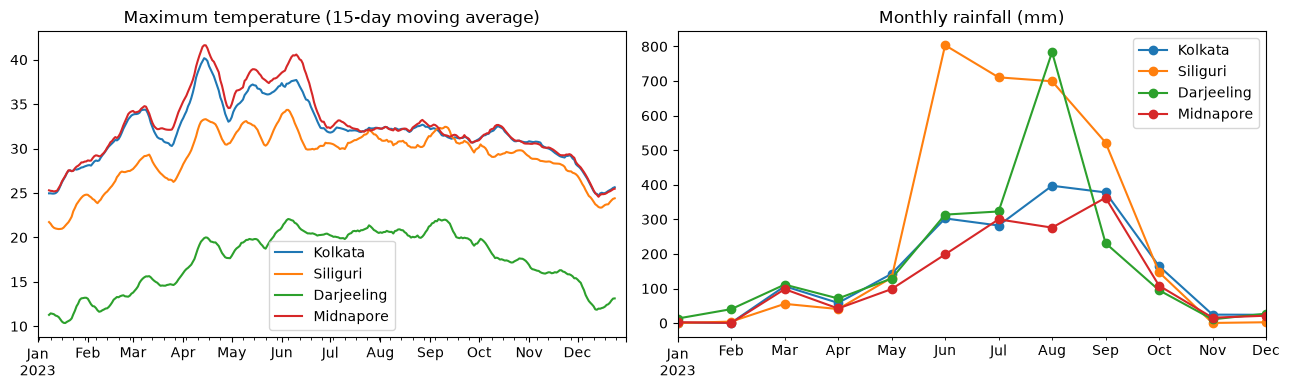

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for city, d in data.items():
    d["tmax"].rolling(15, center=True).mean().plot(ax=axes[0], label=city)
    d["rain"].resample("ME").sum().plot(ax=axes[1], marker="o", label=city)
axes[0].set_title("Maximum temperature (15-day moving average)")
axes[1].set_title("Monthly rainfall (mm)")
for ax in axes:
    ax.legend()
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [9]:
comparison = pd.DataFrame({city: {
    "Average max (°C)": d["tmax"].mean(),
    "Average min (°C)": d["tmin"].mean(),
    "Hottest day (°C)": d["tmax"].max(),
    "Coldest night (°C)": d["tmin"].min(),
    "Total rain (mm)": d["rain"].sum(),
    "Rainy days": (d["rain"] > 1).sum(),
} for city, d in data.items()}).round(1)
comparison

,Kolkata,Siliguri,Darjeeling,Midnapore
Average max (°C),31.7,28.8,17.2,32.3
Average min (°C),22.4,20.0,9.1,22.1
Hottest day (°C),42.6,37.4,24.2,44.9
Coldest night (°C),10.4,9.1,-2.5,10.3
Total rain (mm),1882.3,3117.6,2149.3,1524.3
Rainy days,156.0,153.0,198.0,136.0


## **What the Data Shows**
- Most of Kolkata's rain falls in the **monsoon** months (June to September).
- **Siliguri** gets much more rain than Kolkata, because it lies at the foot of the Himalayas, where the monsoon winds are forced to rise.
- **Darjeeling's** average maximum temperature is about **15 °C lower** than Kolkata's, because of its height (about 2000 m). Its coldest night went below zero.
- **Midnapore** reached a higher peak temperature than Kolkata, because it is further from the sea.

**Source:** Open-Meteo historical weather API (ERA5 reanalysis). These are values for a grid cell, so they can be a little different from the readings of an IMD weather station.